# 01. Exploratory Data Analysis & Learning Problem Formulation

**Judul Proyek:** Deteksi Dini Risiko Kecemasan Sedang–Berat pada Gamer Online Berdasarkan Pola Bermain dan Faktor Psikologis Menggunakan Pendekatan Multi-Model

**Kelompok:** Kelompok 2 / TRPL 5B
- Mohammad Hanif Huda A (NIM: 244311049)
- Muhammad Akbar Fadilah (NIM: 244311051)

**Mata Kuliah:** Data Science (Semester Gasal 2026/2027)

**Fokus Lifecycle:** **[L] Learning Problem & Data Understanding (Bab 4)**

**SDG:** SDG 3 – Kehidupan Sehat dan Sejahtera (Target 3.4: Promosi Kesehatan Mental)

## 1. Inisialisasi Environment & Library

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('tab10')
pd.set_option('display.max_columns', 60)

# Cek jalur file dataset
data_path = '../data/GamingStudy_data.csv' if os.path.exists('../data/GamingStudy_data.csv') else 'data/GamingStudy_data.csv'
print(f"File dataset ditemukan pada: {data_path}")

File dataset ditemukan pada: ../data/GamingStudy_data.csv


## 2. Memuat Dataset & Analisis Dimensi (Bab 4.1)

In [2]:
df_raw = pd.read_csv(data_path, encoding='latin1')
print(f"Dimensi Dataset Mentah: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"Ukuran Memori: {df_raw.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
df_raw.head(3)

Dimensi Dataset Mentah: 13464 baris x 55 kolom
Ukuran Memori: 8.26 MB


,S. No.,Timestamp,GAD1,GAD2,GAD3,GAD4,GAD5,GAD6,GAD7,GADE,SWL1,SWL2,SWL3,SWL4,SWL5,Game,Platform,Hours,earnings,whyplay,League,highestleague,streams,SPIN1,SPIN2,SPIN3,SPIN4,SPIN5,SPIN6,SPIN7,SPIN8,SPIN9,SPIN10,SPIN11,SPIN12,SPIN13,SPIN14,SPIN15,SPIN16,SPIN17,Narcissism,Gender,Age,Work,Degree,Birthplace,Residence,Reference,Playstyle,accept,GAD_T,SWL_T,SPIN_T,Residence_ISO3,Birthplace_ISO3
0,1,42052.00437,0,0,0,0,1,0,0,Not difficult at all,3,5,5,5,5,Skyrim,"Console (PS, Xbox, ...)",15.0,I play for fun,having fun,NaN,NaN,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,Male,25,Unemployed / between jobs,Bachelor (or equivalent),USA,USA,Reddit,Singleplayer,Accept,1,23,5.0,USA,USA
1,2,42052.00680,1,2,2,2,0,1,0,Somewhat difficult,3,5,2,5,1,Other,PC,8.0,I play for fun,having fun,NaN,NaN,2.0,2.0,1.0,1.0,3.0,2.0,3.0,1.0,3.0,4.0,0.0,3.0,0.0,1.0,3.0,3.0,1.0,2.0,1.0,Male,41,Unemployed / between jobs,Bachelor (or equivalent),USA,USA,Reddit,Multiplayer - online - with strangers,Accept,8,16,33.0,USA,USA
2,3,42052.03860,0,2,2,0,0,3,1,Not difficult at all,2,6,5,2,2,Other,PC,0.0,I play for fun,having fun,NaN,NaN,0.0,1.0,0.0,1.0,2.0,3.0,4.0,2.0,1.0,0.0,1.0,1.0,3.0,0.0,2.0,4.0,4.0,2.0,4.0,Female,32,Employed,Bachelor (or equivalent),Germany,Germany,Reddit,Singleplayer,Accept,8,17,31.0,DEU,DEU


## 3. Evaluasi Kondisi Data: Status Responden, Missing Values & Outliers (Bab 4.3)

In [3]:
# 1. Evaluasi status responden 'accept'
print("=== Distribusi Status Responden (accept) ===")
print(df_raw['accept'].value_counts(dropna=False))

# Filter hanya responden berkategori 'Accept'
df = df_raw[df_raw['accept'] == 'Accept'].copy()
print(f"\nJumlah sampel setelah filter Accept: {len(df)} baris")

# 2. Cek Missing Values pada subset Accept
null_series = df.isnull().sum()
null_series = null_series[null_series > 0].sort_values(ascending=False)
print("\n=== Kolom dengan Missing Values pada Data Terfilter ===")
for col, val in null_series.items():
    print(f"{col:20s}: {val:5d} ({val/len(df)*100:.2f}%)")

=== Distribusi Status Responden (accept) ===
accept
Accept    13050
NaN         414
Name: count, dtype: int64

Jumlah sampel setelah filter Accept: 13050 baris

=== Kolom dengan Missing Values pada Data Terfilter ===
highestleague       : 13050 (100.00%)
League              :  1800 (13.79%)
Degree              :  1536 (11.77%)
GADE                :   631 (4.84%)
SPIN_T              :   618 (4.74%)
SPIN13              :   181 (1.39%)
SPIN11              :   181 (1.39%)
SPIN17              :   168 (1.29%)
SPIN12              :   161 (1.23%)
SPIN5               :   158 (1.21%)
SPIN10              :   153 (1.17%)
SPIN14              :   151 (1.16%)
SPIN4               :   150 (1.15%)
SPIN9               :   148 (1.13%)
SPIN6               :   148 (1.13%)
SPIN2               :   146 (1.12%)
SPIN15              :   142 (1.09%)
SPIN16              :   142 (1.09%)
SPIN8               :   138 (1.06%)
SPIN3               :   133 (1.02%)
SPIN7               :   131 (1.00%)
SPIN1               :  

## 4. Formulasi Target Klasifikasi Biner (`risiko_tinggi`)

In [4]:
# Berdasarkan literatur medis Spitzer et al. (2006):
# GAD-7 >= 10 merepresentasikan Moderate to Severe Anxiety (Risiko Tinggi)
df['risiko_tinggi'] = (df['GAD_T'] >= 10).astype(int)

n_neg = (df['risiko_tinggi'] == 0).sum()
n_pos = (df['risiko_tinggi'] == 1).sum()
total = len(df)

print("=== Distribusi Kelas Target ===")
print(f"Kelas 0 (Risiko Rendah/Minimal): {n_neg:,} ({n_neg/total*100:.2f}%)")
print(f"Kelas 1 (Risiko Sedang-Berat)  : {n_pos:,} ({n_pos/total*100:.2f}%)")
print(f"Rasio Ketimpangan Kelas        : 1 : {n_neg/n_pos:.2f}")

=== Distribusi Kelas Target ===
Kelas 0 (Risiko Rendah/Minimal): 10,765 (82.49%)
Kelas 1 (Risiko Sedang-Berat)  : 2,285 (17.51%)
Rasio Ketimpangan Kelas        : 1 : 4.71


## 5. Visualisasi 1: Distribusi Target & Ketimpangan Kelas (Bab 4.4 - Visualisasi 1)

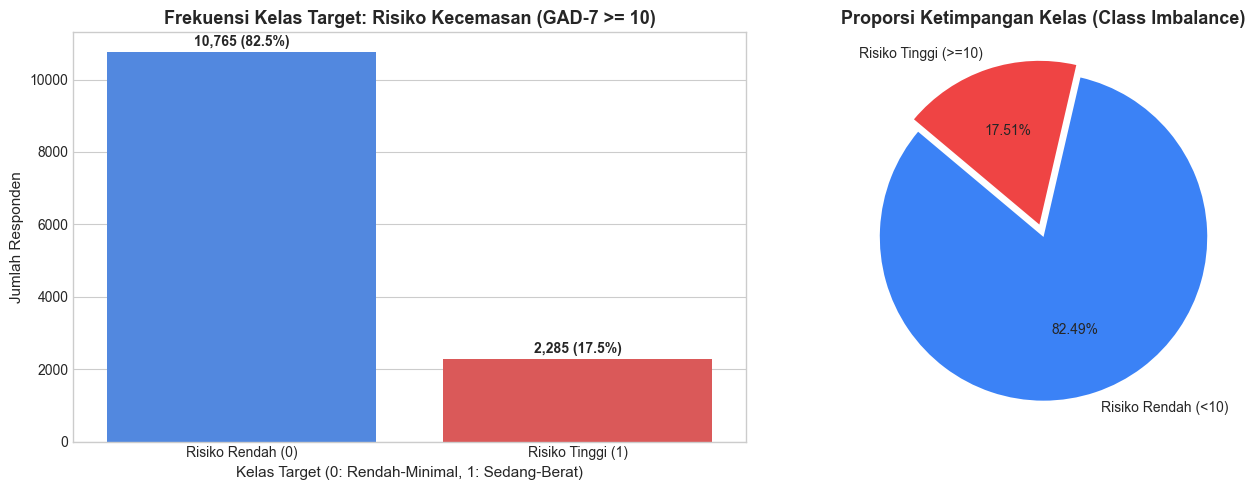

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barplot frekuensi target
counts = df['risiko_tinggi'].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=['#3b82f6', '#ef4444'])
axes[0].set_title('Frekuensi Kelas Target: Risiko Kecemasan (GAD-7 >= 10)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Kelas Target (0: Rendah-Minimal, 1: Sedang-Berat)', fontsize=11)
axes[0].set_ylabel('Jumlah Responden', fontsize=11)
axes[0].set_xticklabels(['Risiko Rendah (0)', 'Risiko Tinggi (1)'])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 150, f"{v:,} ({v/total*100:.1f}%)", ha='center', fontweight='bold')

# Pie chart proporsi
axes[1].pie(counts.values, labels=['Risiko Rendah (<10)', 'Risiko Tinggi (>=10)'], autopct='%1.2f%%',
            startangle=140, colors=['#3b82f6', '#ef4444'], explode=(0, 0.08))
axes[1].set_title('Proporsi Ketimpangan Kelas (Class Imbalance)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/01_distribusi_target.png', dpi=300, bbox_inches='tight') if os.path.exists('../reports') else None
plt.show()

### Insight Visualisasi 1:
1. **Ketimpangan Kelas Signifikan (*Class Imbalance*)**: Sebanyak 10.765 responden (82,49%) berada pada kelas risiko minimal–ringan, sedangkan 2.285 responden (17,51%) berada pada kelas risiko sedang–berat. Rasio ketimpangan tercatat sekitar 1 : 4,71.
2. **Implikasi terhadap Evaluasi Pemodelan**: Metrik akurasi standar (*Accuracy*) tidak dapat diandalkan secara mandiri karena model *dummy* yang selalu memprediksi kelas mayoritas (0) akan langsung mendapatkan akurasi 82,49% namun gagal total mendeteksi gamer berisiko. Oleh karena itu, metrik **Macro-F1**, **Recall (Kelas Positif)**, **ROC-AUC**, dan **PR-AUC** wajib digunakan sebagai tolok ukur utama.

## 6. Visualisasi 2: Distribusi Jam Bermain & Deteksi Outliers (Bab 4.4 - Visualisasi 2)

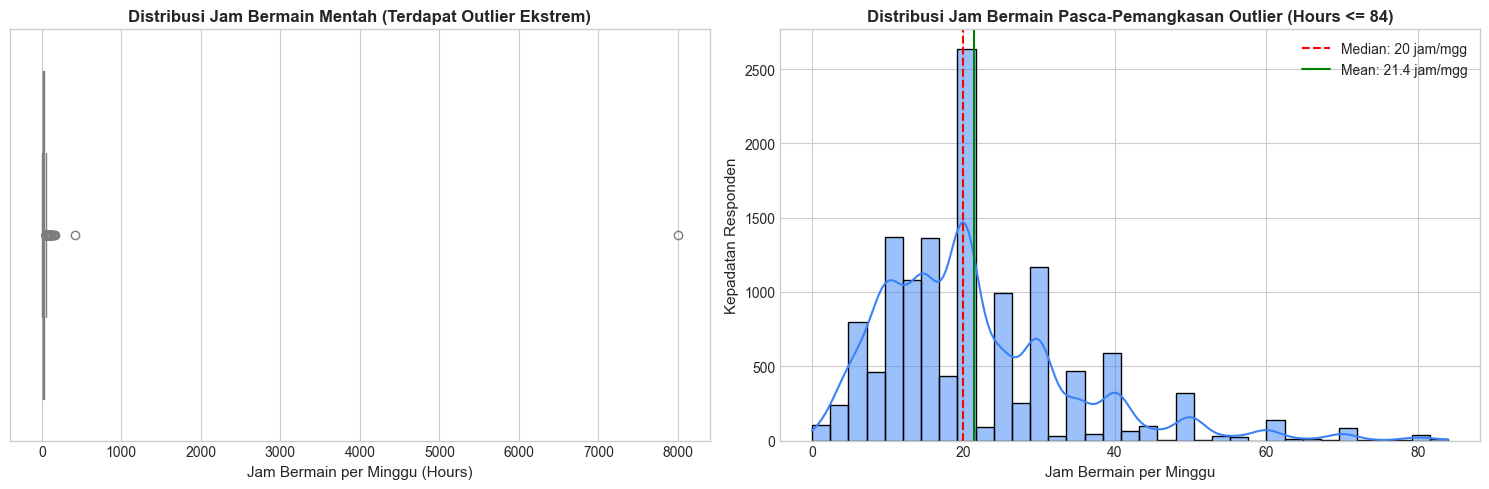

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot jam bermain mentah
sns.boxplot(x=df['Hours'].dropna(), ax=axes[0], color='#fca5a5')
axes[0].set_title('Distribusi Jam Bermain Mentah (Terdapat Outlier Ekstrem)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jam Bermain per Minggu (Hours)', fontsize=11)

# Filter rasional (<= 84 jam/minggu ekuivalen maksimal 12 jam/hari)
hours_clean = df['Hours'][(df['Hours'] <= 84) & (df['Hours'].notnull())]
sns.histplot(hours_clean, bins=35, kde=True, ax=axes[1], color='#3b82f6')
axes[1].axvline(hours_clean.median(), color='red', linestyle='--', label=f'Median: {hours_clean.median():.0f} jam/mgg')
axes[1].axvline(hours_clean.mean(), color='green', linestyle='-', label=f'Mean: {hours_clean.mean():.1f} jam/mgg')
axes[1].set_title('Distribusi Jam Bermain Pasca-Pemangkasan Outlier (Hours <= 84)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jam Bermain per Minggu', fontsize=11)
axes[1].set_ylabel('Kepadatan Responden', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.savefig('../reports/figures/02_jam_bermain_outlier.png', dpi=300, bbox_inches='tight') if os.path.exists('../reports') else None
plt.show()

### Insight Visualisasi 2:
1. **Keberadaan Nilai Ekstrem Palsu (*Spurious Outliers*)**: Pada data mentah, nilai maksimum jam bermain mencapai 8.000 jam/minggu (secara fisik mustahil karena 1 minggu hanya memiliki 168 jam). Terdapat 42 baris dengan `Hours > 84` yang merupakan indikasi kuat ketidakseriusan pengisian kuesioner atau kesalahan ketik.
2. **Pola Jam Bermain Rasional**: Pasca-pemangkasan batas logis ($Hours \le 84$ jam/minggu atau rata-rata $\le 12$ jam/hari), distribusi menunjukkan median bermain 20 jam/minggu, dengan kuartil bawah (Q1) 12 jam dan kuartil atas (Q3) 28 jam. Mayoritas pemain game daring menghabiskan waktu sekitar 2 hingga 4 jam per hari.

## 7. Visualisasi 3: Matriks Korelasi Faktor Psikologis vs Kecemasan (Bab 4.4 - Visualisasi 3)

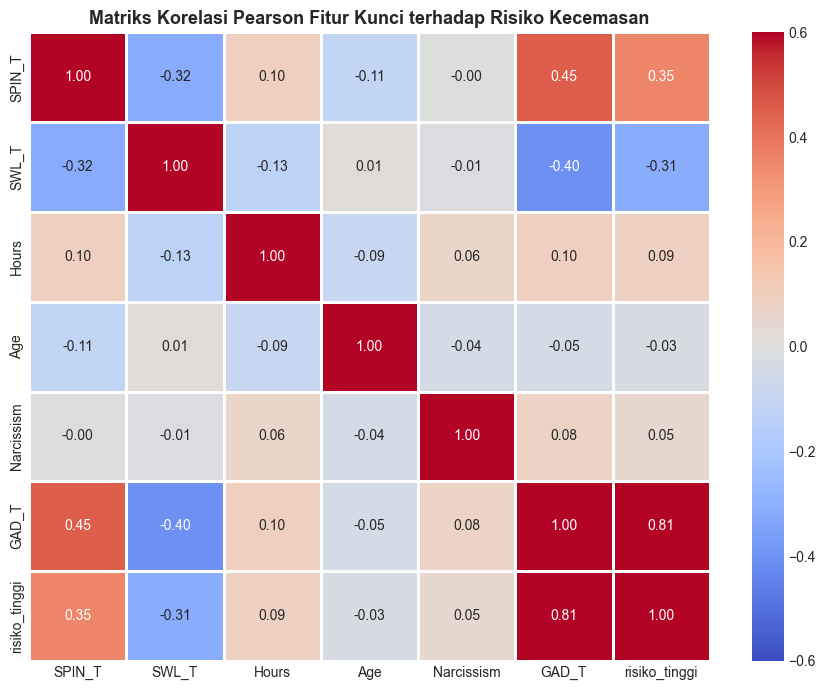

In [7]:
# Pilih fitur numerik kunci
corr_cols = ['SPIN_T', 'SWL_T', 'Hours', 'Age', 'Narcissism', 'GAD_T', 'risiko_tinggi']
corr_df = df[df['Hours'] <= 84][corr_cols].dropna().corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.6, vmax=0.6, linewidths=0.8)
plt.title('Matriks Korelasi Pearson Fitur Kunci terhadap Risiko Kecemasan', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/03_korelasi_psikologis_gad.png', dpi=300, bbox_inches='tight') if os.path.exists('../reports') else None
plt.show()

### Insight Visualisasi 3:
1. **Dominasi Skala Fobia Sosial (`SPIN_T`)**: Menunjukkan korelasi positif paling kuat terhadap skor kecemasan GAD-7 ($r = +0,45$) dan target risiko tinggi ($r = +0,35$). Pemain yang memiliki fobia sosial dan kecemasan interaksi sosial di dunia nyata memiliki probabilitas jauh lebih tinggi mengalami gangguan kecemasan umum.
2. **Efek Protektif Kepuasan Hidup (`SWL_T`)**: Memiliki korelasi negatif yang signifikan ($r = -0,40$). Individu yang merasa puas terhadap kehidupannya secara konsisten memiliki risiko kecemasan yang jauh lebih rendah.
3. **Korelasi Jam Bermain Lemah**: Menariknya, jam bermain mingguan (`Hours`) hanya memiliki korelasi linear yang sangat lemah terhadap skor kecemasan ($r = +0,10$). Hal ini membuktikan secara empiris bahwa lamanya jam bermain game bukanlah faktor penentu tunggal timbulnya kecemasan, melainkan faktor kerentanan psikologis yang mendasarinya.

## 8. Ringkasan Temuan EDA & Rekomendasi Pemodelan

1. **Eliminasi Label Leakage**: Seluruh variabel `GAD1`–`GAD7`, `GAD_T`, dan `GADE` harus dikeluarkan sebelum pelatihan model.
2. **Pembersihan Outlier**: Pemangkasan jam bermain `Hours <= 84` wajib diterapkan.
3. **Skema Pembobotan Kelas**: Penanganan ketimpangan kelas (17,5% positif) menggunakan pembobotan kelas (*class weights*) pada Logistic Regression, Random Forest, dan ResNet.
4. **Pentingnya Integrasi Multi-Fitur**: Kombinasi pola bermain dengan faktor psikologis terbukti mutlak diperlukan untuk menghasilkan diskriminasi yang baik.